In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

In [9]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

In [10]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout

In [13]:
from google.colab import files

uploaded = files.upload()

Saving dataset.csv to dataset.csv


In [14]:
df = pd.read_csv("dataset.csv")

In [15]:
print("Dataset loaded successfully!")
print("\nFirst five rows:")
display(df.head())

Dataset loaded successfully!

First five rows:


,Text,language
0,klement gottwaldi surnukeha palsameeriti ning ...,Estonian
1,sebes joseph pereira thomas på eng the jesuit...,Swedish
2,ถนนเจริญกรุง อักษรโรมัน thanon charoen krung เ...,Thai
3,விசாகப்பட்டினம் தமிழ்ச்சங்கத்தை இந்துப் பத்திர...,Tamil
4,de spons behoort tot het geslacht haliclona en...,Dutch


In [16]:
print("Column names:", df.columns.tolist())
print("Dataset shape:", df.shape)

Column names: ['Text', 'language']
Dataset shape: (22000, 2)


In [17]:
print("Column names:")
print(df.columns.tolist())

Column names:
['Text', 'language']


In [18]:
print("\nDataset information:")
df.info()


Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 22000 entries, 0 to 21999
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   Text      22000 non-null  object
 1   language  22000 non-null  object
dtypes: object(2)
memory usage: 343.9+ KB


In [19]:
# Display missing values before cleaning
print("Missing values before cleaning:")
print(df.isnull().sum())

Missing values before cleaning:
Text        0
language    0
dtype: int64


In [20]:
# Remove rows with missing values
df = df.dropna()


In [21]:
# Remove duplicate rows
df = df.drop_duplicates()

In [22]:
print("\nMissing values after cleaning:")
print(df.isnull().sum())


Missing values after cleaning:
Text        0
language    0
dtype: int64


In [23]:
print("\nDataset shape after cleaning:", df.shape)


Dataset shape after cleaning: (21859, 2)


In [26]:
print("Column names:", df.columns.tolist())

Column names: ['Text', 'language']


In [27]:
TEXT_COL = "Text"
LABEL_COL = "language"

# Keep only the required columns
data = df[[TEXT_COL, LABEL_COL]].copy()

# Remove rows with missing values
data = data.dropna(subset=[TEXT_COL, LABEL_COL])

# Convert values to strings and remove extra spaces
data[TEXT_COL] = data[TEXT_COL].astype(str).str.strip()
data[LABEL_COL] = data[LABEL_COL].astype(str).str.strip()

# Remove empty text and labels
data = data[
    (data[TEXT_COL] != "") &
    (data[LABEL_COL] != "")
]

# Remove duplicate samples
data = data.drop_duplicates()

data = data.reset_index(drop=True)

print("Cleaned dataset shape:", data.shape)
display(data.head())

Cleaned dataset shape: (21858, 2)


,Text,language
0,klement gottwaldi surnukeha palsameeriti ning ...,Estonian
1,sebes joseph pereira thomas på eng the jesuit...,Swedish
2,ถนนเจริญกรุง อักษรโรมัน thanon charoen krung เ...,Thai
3,விசாகப்பட்டினம் தமிழ்ச்சங்கத்தை இந்துப் பத்திர...,Tamil
4,de spons behoort tot het geslacht haliclona en...,Dutch


In [28]:
MAX_SAMPLES = 10000

if len(data) > MAX_SAMPLES:
    data = data.sample(
        n=MAX_SAMPLES,
        random_state=42
    ).reset_index(drop=True)

print("Samples selected:", len(data))
print("\nNumber of languages:", data[LABEL_COL].nunique())

print("\nSamples per language:")
print(data[LABEL_COL].value_counts())

Samples selected: 10000

Number of languages: 22

Samples per language:
language
Latin         496
Korean        474
English       473
Estonian      471
Turkish       470
Romanian      465
Spanish       464
Thai          463
Persian       461
Indonesian    459
Swedish       456
Arabic        454
Russian       452
Dutch         449
Japanese      446
French        444
Urdu          442
Portugese     441
Tamil         436
Hindi         435
Chinese       428
Pushto        421
Name: count, dtype: int64


In [29]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

X = data[TEXT_COL].values
y = data[LABEL_COL].values

# Convert language labels into numerical values
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.2,
    random_state=42,
    stratify=y_encoded
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Number of classes:", len(label_encoder.classes_))
print("Languages:", label_encoder.classes_)

Training samples: 8000
Testing samples: 2000
Number of classes: 22
Languages: ['Arabic' 'Chinese' 'Dutch' 'English' 'Estonian' 'French' 'Hindi'
 'Indonesian' 'Japanese' 'Korean' 'Latin' 'Persian' 'Portugese' 'Pushto'
 'Romanian' 'Russian' 'Spanish' 'Swedish' 'Tamil' 'Thai' 'Turkish' 'Urdu']


In [30]:
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

MAX_WORDS = 20000
MAX_LEN = 100

# Create tokenizer
tokenizer = Tokenizer(
    num_words=MAX_WORDS,
    oov_token="<OOV>"
)

# Learn vocabulary only from training text
tokenizer.fit_on_texts(X_train)

# Convert text to numerical sequences
X_train_seq = tokenizer.texts_to_sequences(X_train)
X_test_seq = tokenizer.texts_to_sequences(X_test)

# Pad sequences to equal length
X_train_pad = pad_sequences(
    X_train_seq,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

X_test_pad = pad_sequences(
    X_test_seq,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

print("Training sequence shape:", X_train_pad.shape)
print("Testing sequence shape:", X_test_pad.shape)

print("\nExample text:", X_train[0])
print("Numerical sequence:", X_train_seq[0])
print("Padded sequence:", X_train_pad[0])

Training sequence shape: (8000, 100)
Testing sequence shape: (2000, 100)

Example text: de variëteit van termen is voornamelijk het resultaat van groeperen van softwaremechanismen die te maken hebben met een specifiek aspect van softwareontwikkeling automatisering in het bijzonder heeft te maken met de werking van een toepassing of component als api te exporteren zodat het door een andere toepassing of een menselijke gebruiker kan gebruikt worden
Numerical sequence: [2, 1, 32, 5778, 53, 16252, 51, 1, 32, 1, 32, 1, 107, 179, 4434, 1390, 164, 62, 1, 16253, 32, 1, 1, 8, 51, 1, 809, 179, 4434, 164, 2, 12220, 32, 62, 12221, 13, 7941, 325, 1067, 179, 1, 16254, 51, 195, 62, 1203, 12221, 13, 62, 1, 1, 786, 4435, 735]
Padded sequence: [    2     1    32  5778    53 16252    51     1    32     1    32     1
   107   179  4434  1390   164    62     1 16253    32     1     1     8
    51     1   809   179  4434   164     2 12220    32    62 12221    13
  7941   325  1067   179     1 16254    51   

In [31]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout

num_classes = len(label_encoder.classes_)

model = Sequential([
    Embedding(
        input_dim=MAX_WORDS,
        output_dim=64,
        mask_zero=True
    ),

    LSTM(64),

    Dropout(0.3),

    Dense(32, activation="relu"),

    Dense(num_classes, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [32]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

history = model.fit(
    X_train_pad,
    y_train,
    epochs=10,
    batch_size=64,
    validation_split=0.1,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/10
113/113 ━━━━━━━━━━━━━━━━━━━━ 17s 118ms/step - accuracy: 0.1697 - loss: 2.6888 - val_accuracy: 0.4538 - val_loss: 1.9595
Epoch 2/10
113/113 ━━━━━━━━━━━━━━━━━━━━ 20s 116ms/step - accuracy: 0.5932 - loss: 1.3116 - val_accuracy: 0.7588 - val_loss: 0.8638
Epoch 3/10
113/113 ━━━━━━━━━━━━━━━━━━━━ 13s 113ms/step - accuracy: 0.7492 - loss: 0.8045 - val_accuracy: 0.8650 - val_loss: 0.5320
Epoch 4/10
113/113 ━━━━━━━━━━━━━━━━━━━━ 13s 116ms/step - accuracy: 0.8388 - loss: 0.5407 - val_accuracy: 0.8525 - val_loss: 0.5551
Epoch 5/10
113/113 ━━━━━━━━━━━━━━━━━━━━ 21s 116ms/step - accuracy: 0.8922 - loss: 0.3639 - val_accuracy: 0.9200 - val_loss: 0.3057
Epoch 6/10
113/113 ━━━━━━━━━━━━━━━━━━━━ 13s 114ms/step - accuracy: 0.9211 - loss: 0.2520 - val_accuracy: 0.9125 - val_loss: 0.2942
Epoch 7/10
113/113 ━━━━━━━━━━━━━━━━━━━━ 13s 114ms/step - accuracy: 0.8928 - loss: 0.3338 - val_accuracy: 0.9187 - val_loss: 0.2987
Epoch 8/10
113/113 ━━━━━━━━━━━━━━━━━━━━ 13s 114ms/step - accuracy: 0.9336 - loss: 0

In [33]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Evaluate test data
test_loss, test_accuracy = model.evaluate(
    X_test_pad,
    y_test,
    verbose=0
)

# Predict class probabilities
y_prob = model.predict(X_test_pad, verbose=0)

# Convert probabilities to predicted class labels
y_pred = np.argmax(y_prob, axis=1)

# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test, y_pred, average="weighted", zero_division=0
)

recall = recall_score(
    y_test, y_pred, average="weighted", zero_division=0
)

f1 = f1_score(
    y_test, y_pred, average="weighted", zero_division=0
)

print(f"Test Accuracy : {accuracy:.4f}")
print(f"Precision     : {precision:.4f}")
print(f"Recall        : {recall:.4f}")
print(f"F1-Score      : {f1:.4f}")

Test Accuracy : 0.9125
Precision     : 0.9162
Recall        : 0.9125
F1-Score      : 0.9131


In [34]:
print(classification_report(
    y_test,
    y_pred,
    labels=np.arange(num_classes),
    target_names=label_encoder.classes_,
    zero_division=0
))

              precision    recall  f1-score   support

      Arabic       0.95      0.99      0.97        91
     Chinese       0.50      0.63      0.56        86
       Dutch       0.99      0.98      0.98        90
     English       0.96      0.97      0.96        95
    Estonian       1.00      0.89      0.94        94
      French       0.98      0.98      0.98        89
       Hindi       1.00      1.00      1.00        87
  Indonesian       0.98      0.97      0.97        92
    Japanese       0.47      0.37      0.42        89
      Korean       1.00      0.97      0.98        95
       Latin       0.92      0.92      0.92        99
     Persian       0.98      0.98      0.98        92
   Portugese       0.96      0.91      0.94        88
      Pushto       0.96      0.94      0.95        84
    Romanian       0.98      0.97      0.97        93
     Russian       0.98      0.96      0.97        90
     Spanish       0.97      0.98      0.97        93
     Swedish       1.00    

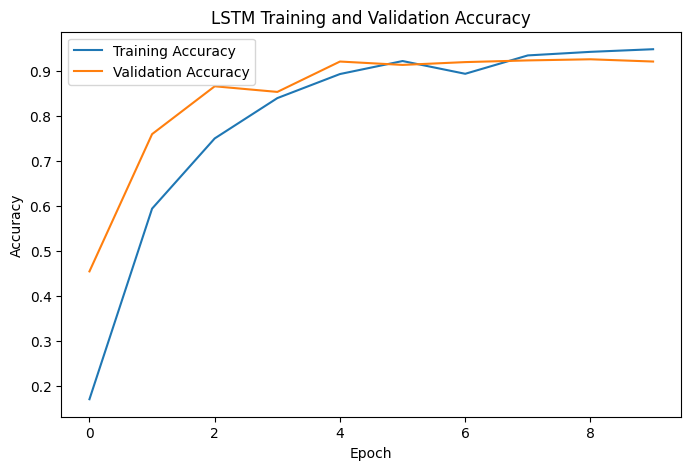

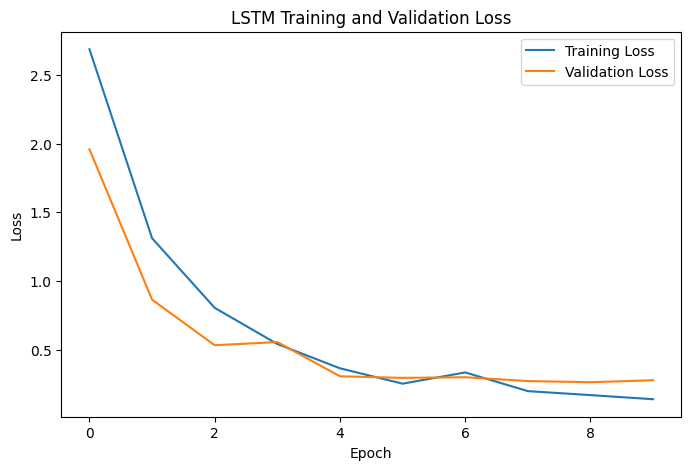

In [35]:
import matplotlib.pyplot as plt

# Accuracy graph
plt.figure(figsize=(8, 5))
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("LSTM Training and Validation Accuracy")
plt.legend()
plt.show()

# Loss graph
plt.figure(figsize=(8, 5))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("LSTM Training and Validation Loss")
plt.legend()
plt.show()

In [36]:
def identify_language(text):
    sequence = tokenizer.texts_to_sequences([text])

    padded = pad_sequences(
        sequence,
        maxlen=MAX_LEN,
        padding="post",
        truncating="post"
    )

    probabilities = model.predict(padded, verbose=0)[0]

    predicted_index = np.argmax(probabilities)
    predicted_language = label_encoder.inverse_transform(
        [predicted_index]
    )[0]

    confidence = probabilities[predicted_index] * 100

    print("Input text:", text)
    print("Predicted language:", predicted_language)
    print(f"Model confidence: {confidence:.2f}%")

# Test examples
identify_language("Hello, how are you?")
identify_language("Bonjour, comment allez-vous?")
identify_language("Hola, ¿cómo estás?")

Input text: Hello, how are you?
Predicted language: Chinese
Model confidence: 35.98%
Input text: Bonjour, comment allez-vous?
Predicted language: Japanese
Model confidence: 50.92%
Input text: Hola, ¿cómo estás?
Predicted language: Japanese
Model confidence: 51.00%


In [37]:
import pickle

model.save("language_identification_lstm.keras")

with open("tokenizer.pkl", "wb") as f:
    pickle.dump(tokenizer, f)

with open("label_encoder.pkl", "wb") as f:
    pickle.dump(label_encoder, f)

print("Model and preprocessing objects saved successfully.")

Model and preprocessing objects saved successfully.


In [38]:
from google.colab import files

files.download("language_identification_lstm.keras")
files.download("tokenizer.pkl")
files.download("label_encoder.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [39]:
# TASK 1: Dataset loading, missing values and preprocessing
print("TASK 1: DATA PREPROCESSING")
print("Cleaned dataset shape:", data.shape)
print("Missing values:\n", data[[TEXT_COL, LABEL_COL]].isnull().sum())
print("Empty text samples:", (data[TEXT_COL].str.strip() == "").sum())
print("Number of languages:", data[LABEL_COL].nunique())

# TASK 2: Tokenization and padding
print("\nTASK 2: TOKENIZATION AND PADDING")
print("Training sequences:", X_train_pad.shape)
print("Testing sequences:", X_test_pad.shape)
print("Vocabulary size:", len(tokenizer.word_index))

# TASK 3: LSTM model
print("\nTASK 3: LSTM MODEL")
model.summary()

# TASK 4: Training and evaluation
print("\nTASK 4: MODEL EVALUATION")
print(f"Test Accuracy : {accuracy:.4f}")
print(f"Precision     : {precision:.4f}")
print(f"Recall        : {recall:.4f}")
print(f"F1-score      : {f1:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    labels=np.arange(num_classes),
    target_names=label_encoder.classes_,
    zero_division=0
))

print("\nAll four required task outputs have been checked.")

TASK 1: DATA PREPROCESSING
Cleaned dataset shape: (10000, 2)
Missing values:
 Text        0
language    0
dtype: int64
Empty text samples: 0
Number of languages: 22

TASK 2: TOKENIZATION AND PADDING
Training sequences: (8000, 100)
Testing sequences: (2000, 100)
Vocabulary size: 136006

TASK 3: LSTM MODEL


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 100, 64)        │     1,280,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 22)             │           726 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,947,492 (15.06 MB)

 Trainable params: 1,315,830 (5.02 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 2,631,662 (10.04 MB)


TASK 4: MODEL EVALUATION
Test Accuracy : 0.9125
Precision     : 0.9162
Recall        : 0.9125
F1-score      : 0.9131

Classification Report:
              precision    recall  f1-score   support

      Arabic       0.95      0.99      0.97        91
     Chinese       0.50      0.63      0.56        86
       Dutch       0.99      0.98      0.98        90
     English       0.96      0.97      0.96        95
    Estonian       1.00      0.89      0.94        94
      French       0.98      0.98      0.98        89
       Hindi       1.00      1.00      1.00        87
  Indonesian       0.98      0.97      0.97        92
    Japanese       0.47      0.37      0.42        89
      Korean       1.00      0.97      0.98        95
       Latin       0.92      0.92      0.92        99
     Persian       0.98      0.98      0.98        92
   Portugese       0.96      0.91      0.94        88
      Pushto       0.96      0.94      0.95        84
    Romanian       0.98      0.97      0.97    